# Elliptic++ actor-level graph EDA

Mục tiêu: kiểm tra dữ liệu actor, tạo actor graph và sinh các hình nền cho paper.
Toàn bộ graph có hơn 2.8 triệu edge nên hình mạng sẽ dùng một subgraph có kiểm soát, không vẽ toàn bộ graph.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
os.environ['NUMBA_NUM_THREADS'] = '2'

from pathlib import Path
import sys
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA = ROOT / 'data'
OUT = ROOT / 'figures'
OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120
print(ROOT)
print('Resource profile: 8 GB RAM, 2 CPU threads')

/home/vinhnguyen/Workspace/Personal/elliptic-actor-graph
Resource profile: 8 GB RAM, 2 CPU threads


## 1. Actor labels and temporal feature table

actor-level shape: (822942, 111)


,actors
class,
3,557588
2,251088
1,14266


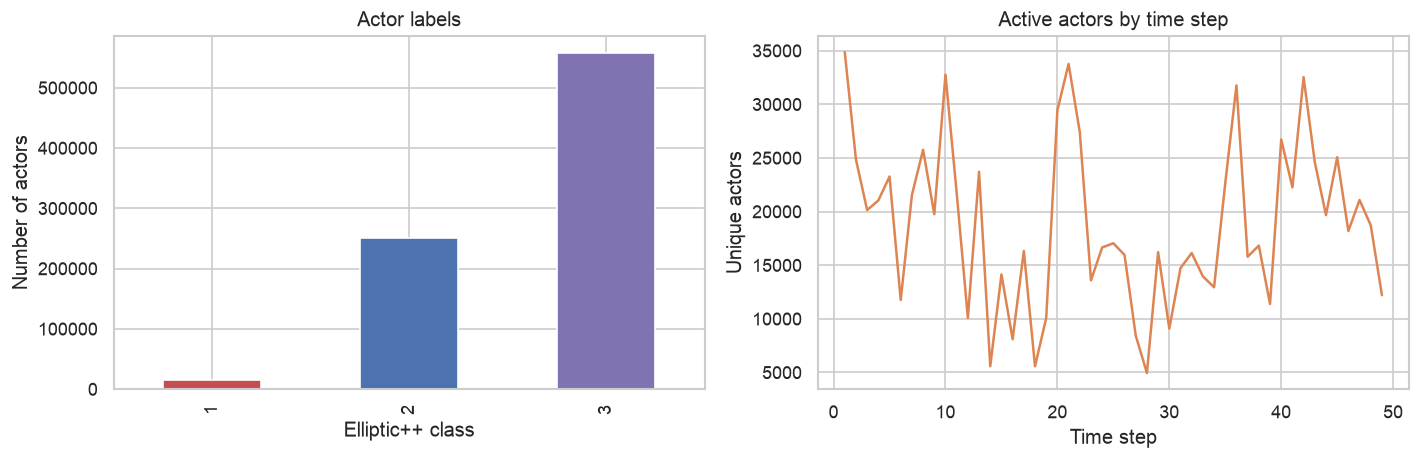

5

In [2]:
from src.actor_features import make_actor_dataset

actor = make_actor_dataset(
    DATA / 'Actors_Dataset' / 'wallets_features_classes_combined.csv',
    DATA / 'Actors_Dataset' / 'wallets_classes.csv',
)
print(f'actor-level shape: {actor.shape}')
display(actor['class'].value_counts().rename_axis('class').to_frame('actors'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
actor['class'].value_counts().sort_index().plot.bar(ax=axes[0], color=['#c44e52', '#4c72b0', '#8172b2'])
axes[0].set_title('Actor labels')
axes[0].set_xlabel('Elliptic++ class')
axes[0].set_ylabel('Number of actors')
timesteps = pd.read_csv(DATA / 'Actors_Dataset' / 'wallets_features_classes_combined.csv', usecols=['address', 'Time step'])
timesteps.groupby('Time step')['address'].nunique().plot(ax=axes[1], color='#dd8452')
axes[1].set_title('Active actors by time step')
axes[1].set_xlabel('Time step')
axes[1].set_ylabel('Unique actors')
fig.tight_layout()
fig.savefig(OUT / 'actor_labels_and_activity.png', bbox_inches='tight')
plt.show()
del timesteps
gc.collect()

## 2. Actor graph statistics

combined actor table: (822942, 116)


,count,mean,std,min,50%,90%,99%,max
weighted_out_degree,822942.0,3.486229,59.775630,0.0,0.0,2.0,42.0,37835.0
weighted_in_degree,822942.0,3.486229,23.551525,0.0,1.0,7.0,46.0,12019.0
out_degree,822942.0,3.372822,47.299159,0.0,0.0,2.0,42.0,22995.0
in_degree,822942.0,3.372822,20.766741,0.0,1.0,7.0,46.0,11213.0
self_loop_count,822942.0,0.055874,3.545937,0.0,0.0,0.0,1.0,1453.0


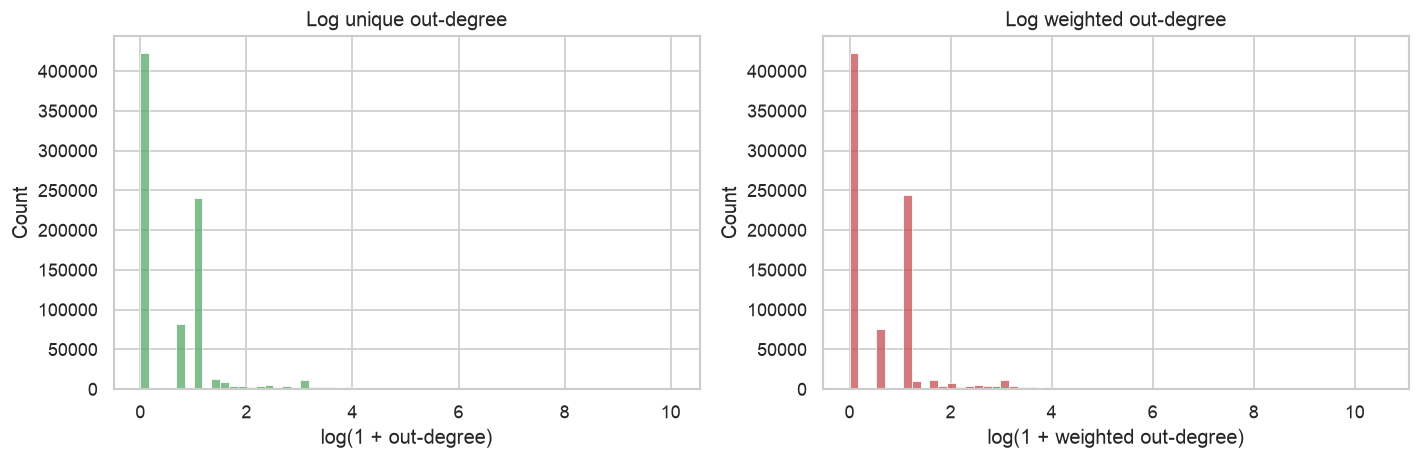

In [3]:
from src.graph_features import build_graph_features

graph_features = build_graph_features(DATA / 'Actors_Dataset' / 'AddrAddr_edgelist.csv')
actor = actor.join(graph_features, how='left').fillna(0)
print(f'combined actor table: {actor.shape}')
display(graph_features.describe(percentiles=[.5, .9, .99]).T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.log1p(graph_features['out_degree']), bins=60, ax=axes[0], color='#55a868')
axes[0].set_title('Log unique out-degree')
axes[0].set_xlabel('log(1 + out-degree)')
sns.histplot(np.log1p(graph_features['weighted_out_degree']), bins=60, ax=axes[1], color='#c44e52')
axes[1].set_title('Log weighted out-degree')
axes[1].set_xlabel('log(1 + weighted out-degree)')
fig.tight_layout()
fig.savefig(OUT / 'actor_degree_distributions.png', bbox_inches='tight')
plt.show()

## 2b. Full actor graph density

The next cell uses every actor edge. It renders an adjacency-density image ordered by degree instead of computing a force-directed layout, so memory stays bounded.

In [6]:
from src.full_graph_render import render_full_adjacency_density

full_graph_summary = render_full_adjacency_density(
    DATA / 'Actors_Dataset' / 'AddrAddr_edgelist.csv',
    graph_features,
    OUT / 'full_actor_graph_adjacency_density.png',
    image_size=(1200, 1200),
    chunksize=250_000,
)
print(full_graph_summary)

{'edges_rendered': 2868964, 'edges_missing_actor': 0, 'image_width': 1200, 'image_height': 1200}


## 3. A readable actor subgraph

We use the top-degree actors and their direct neighbours. This is a visualization sample, not the full graph.

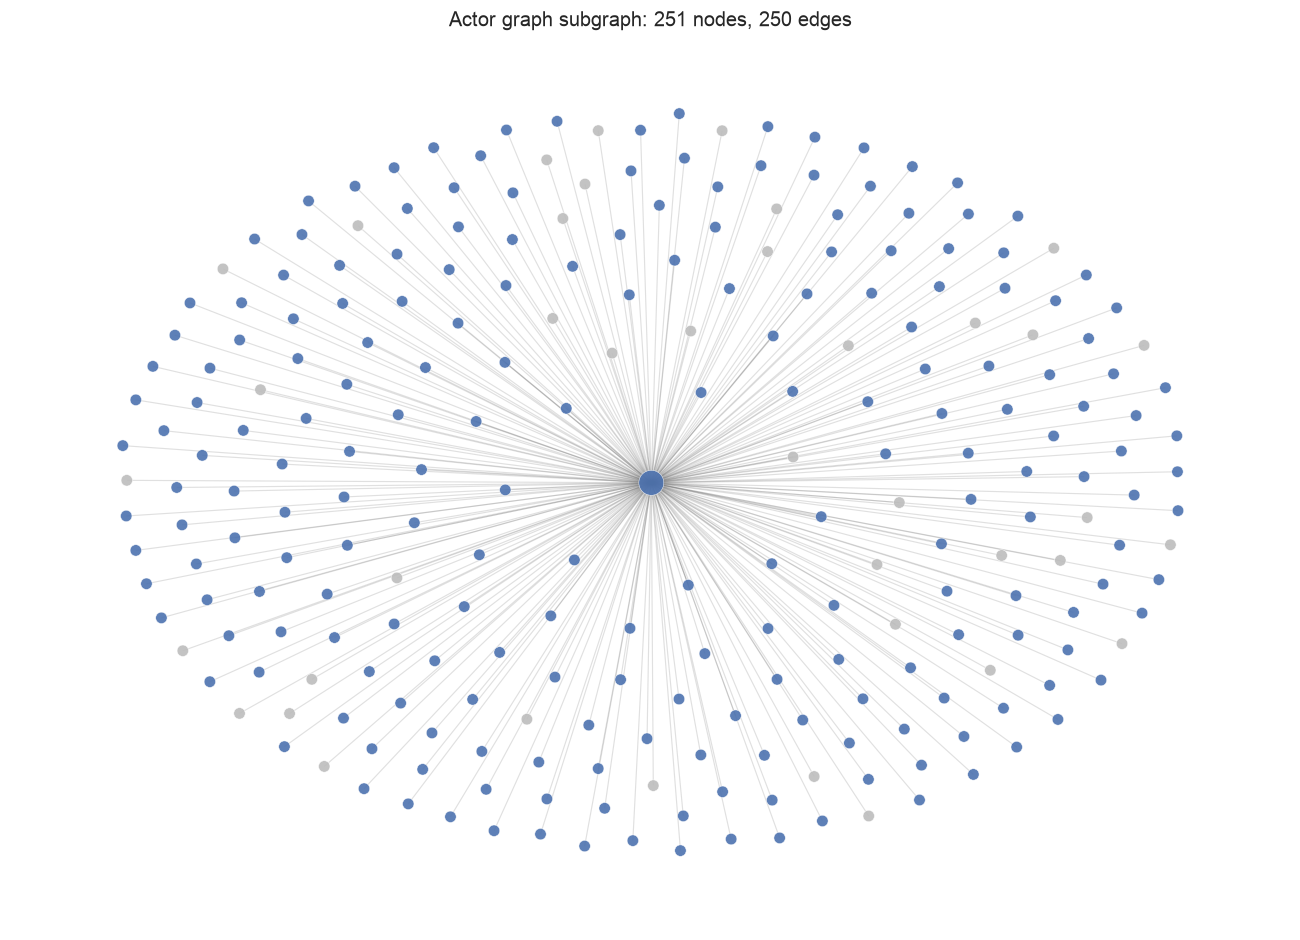

In [4]:
import networkx as nx

edges_path = DATA / 'Actors_Dataset' / 'AddrAddr_edgelist.csv'
top_nodes = set(graph_features.nlargest(25, 'weighted_out_degree').index)
sub_edges = []
for chunk in pd.read_csv(edges_path, usecols=['input_address', 'output_address'], dtype=str, chunksize=250_000):
    selected = chunk[chunk['input_address'].isin(top_nodes) | chunk['output_address'].isin(top_nodes)]
    sub_edges.extend(selected.itertuples(index=False, name=None))
    if len(sub_edges) >= 250:
        break

G = nx.Graph()
G.add_edges_from(sub_edges[:250])
degrees = dict(G.degree())
node_colors = ['#c44e52' if actor.loc[node, 'class'] == 1 else '#4c72b0' if actor.loc[node, 'class'] == 2 else '#bdbdbd' for node in G.nodes if node in actor.index]
node_sizes = [35 + 12 * np.sqrt(degrees[node]) for node in G.nodes]
pos = nx.spring_layout(G, seed=42, k=0.7, iterations=80)
fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.18, width=0.7, edge_color='#555555')
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_sizes, node_color=node_colors, alpha=0.9, linewidths=0.3, edgecolors='white')
ax.set_title(f'Actor graph subgraph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges')
ax.axis('off')
fig.tight_layout()
fig.savefig(OUT / 'actor_graph_top_degree_subgraph.png', bbox_inches='tight')
plt.show()

## 4. Baseline clustering projection

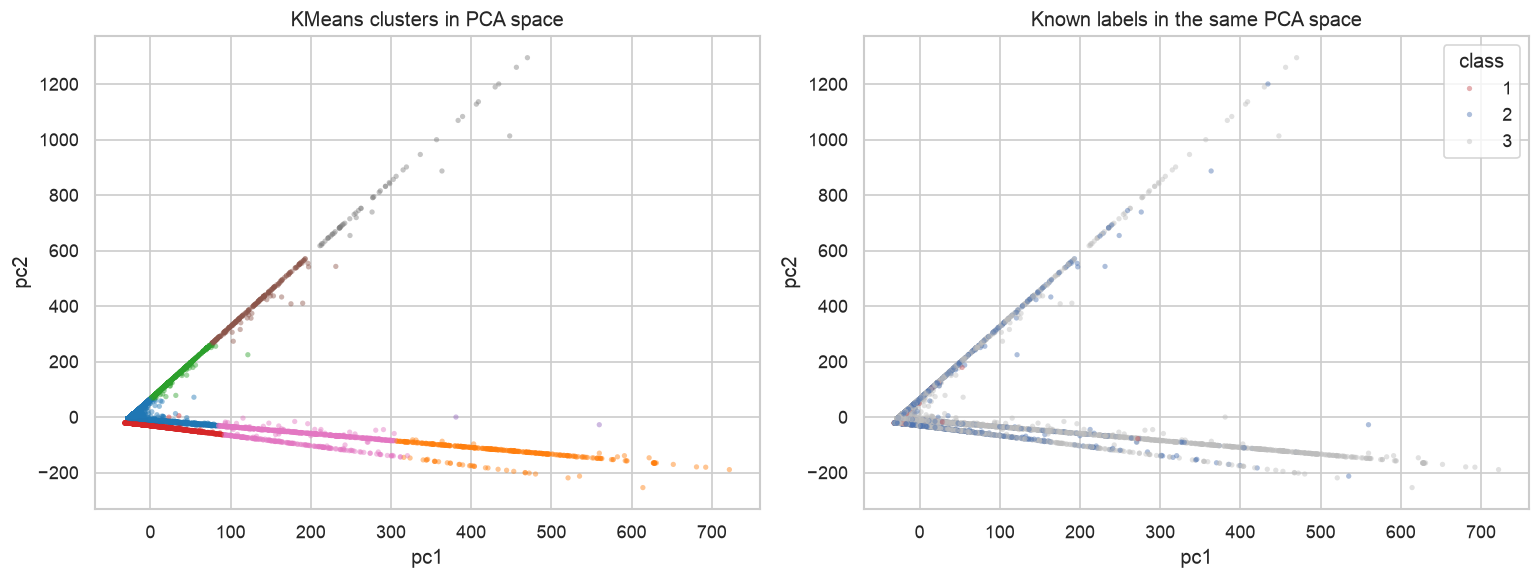

class,1,2,3
cluster,,,
0,256,3637,9680
1,0,16,353
2,3,214,449
3,87,1973,2296
4,0,1,1
5,0,75,153
6,3,126,620
7,0,10,47


In [5]:
from src.clustering import prepare_matrix, fit_kmeans

sample = actor.sample(n=min(20_000, len(actor)), random_state=42)
matrix, pca, _, _ = prepare_matrix(sample)
sample = sample.copy()
sample['cluster'] = fit_kmeans(matrix, n_clusters=8, random_state=42)
sample['pc1'] = matrix[:, 0]
sample['pc2'] = matrix[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=sample, x='pc1', y='pc2', hue='cluster', palette='tab10', s=10, alpha=0.45, linewidth=0, ax=axes[0], legend=False)
axes[0].set_title('KMeans clusters in PCA space')
sns.scatterplot(data=sample, x='pc1', y='pc2', hue='class', palette={1: '#c44e52', 2: '#4c72b0', 3: '#bdbdbd'}, s=10, alpha=0.45, linewidth=0, ax=axes[1])
axes[1].set_title('Known labels in the same PCA space')
fig.tight_layout()
fig.savefig(OUT / 'baseline_clustering_pca.png', bbox_inches='tight')
plt.show()

cluster_table = pd.crosstab(sample['cluster'], sample['class'])
display(cluster_table)

## 5. Reproducible clustering benchmark

This benchmark compares KMeans and HDBSCAN on a fixed sample and reports both unsupervised geometry and known-label agreement. Class 3 remains unknown and is not used as a clustering feature.

In [ ]:
from src.run_experiments import run_benchmark, write_experiment_manifest

metrics, enrichment = run_benchmark(DATA, ROOT / 'results', sample_size=20_000, random_state=42)
write_experiment_manifest(ROOT / 'results', sample_size=20_000, random_state=42)
display(metrics)
display(enrichment.groupby('method', as_index=False).head(3))

## 5b. Full-graph Leiden in the notebook

This cell runs the graph model directly in the notebook, saves actor memberships as CSV, and evaluates communities without using labels during fitting.

In [10]:
from src.community import fit_leiden
from src.actor_features import load_actor_labels
from src.evaluation import cluster_enrichment

addresses = pd.Index(actor.index.astype(str), name='address')
leiden_memberships, leiden_summary = fit_leiden(
    DATA / 'Actors_Dataset' / 'AddrAddr_edgelist.csv',
    addresses,
    resolution=1.0,
)
leiden_labels = load_actor_labels(DATA / 'Actors_Dataset' / 'wallets_classes.csv').reindex(addresses)
leiden_enrichment = cluster_enrichment(leiden_memberships.to_numpy(), leiden_labels)
(ROOT / 'results').mkdir(exist_ok=True)
leiden_memberships.to_csv(ROOT / 'results' / 'leiden_memberships.csv', header=True)
leiden_enrichment.to_csv(ROOT / 'results' / 'leiden_enrichment.csv')
print(leiden_summary)
display(leiden_enrichment[leiden_enrichment['cluster_size'] >= 30].head(15))

{'input_edges_without_self_loops': 2822983, 'unique_undirected_edges': 2772474, 'communities': 887, 'modularity': 0.9212121253879861, 'largest_community': 72619}


,cluster_size,illicit_count,known_count,illicit_rate,global_illicit_rate,enrichment
cluster,,,,,,
40,1730,1142,1730,0.660116,0.053762,12.278446
48,1886,980,1886,0.519618,0.053762,9.665132
88,493,253,493,0.513185,0.053762,9.545463
57,1183,595,1183,0.502959,0.053762,9.355255
79,147,68,147,0.462585,0.053762,8.604289
74,1054,462,1054,0.438330,0.053762,8.153138
29,744,309,744,0.415323,0.053762,7.725186
97,664,265,664,0.399096,0.053762,7.423372
80,741,277,741,0.373819,0.053762,6.953204


## 6. Proposed method: CC-MVAD

**Community-Conditioned Multi-View Actor Discovery (CC-MVAD)** is the proposed contribution. It does not use labels to create representations:

1. Leiden supplies structural context for each actor.
2. PCA supplies a compact behavioural view.
3. Each actor receives its distance from the behavioural centroid of its Leiden community.
4. We evaluate whether structurally coherent communities and their behavioural residuals enrich for illicit actors.

This differs from a standard GNN classifier: the output is an unsupervised actor/community discovery score, with labels used only in the final evaluation cell.

In [11]:
from src.multiview import community_conditioned_residuals, robust_zscore

membership_path = ROOT / 'results' / 'leiden_memberships.csv'
leiden = pd.read_csv(membership_path, index_col='address')['community']
leiden.index = leiden.index.astype(str)

cc_sample = actor.sample(n=min(20_000, len(actor)), random_state=42).copy()
cc_matrix, cc_pca, _, _ = prepare_matrix(cc_sample, random_state=42)
cc_communities = leiden.reindex(cc_sample.index.astype(str)).fillna(-1).to_numpy()
valid = cc_communities >= 0
cc_residuals = np.full(len(cc_sample), np.nan, dtype=np.float32)
cc_residuals[valid], cc_stats = community_conditioned_residuals(cc_matrix[valid], cc_communities[valid])
cc_sample['community'] = cc_communities
cc_sample['behavioral_residual'] = cc_residuals
cc_sample['residual_z'] = robust_zscore(np.nan_to_num(cc_residuals, nan=0.0))
print(f'CC-MVAD sample: {len(cc_sample):,} actors; valid Leiden memberships: {valid.sum():,}')
display(cc_stats.head(10))

CC-MVAD sample: 20,000 actors; valid Leiden memberships: 20,000


,community,community_size,mean_behavioral_residual
178,178,2,447.608109
284,397,2,388.004196
222,238,2,314.304962
266,329,2,269.585571
155,155,5,203.558977
8,8,456,189.174899
78,78,58,186.267740
84,84,60,184.917093
257,307,2,183.992523
210,218,2,172.724655


Top eligible communities by illicit enrichment:


,community,cluster_size,illicit_count,known_count,illicit_rate,global_illicit_rate,enrichment,community_size,mean_behavioral_residual,eligible
2,40,36,21,36,0.583333,0.054523,10.698902,126,73.968591,True
3,48,54,27,54,0.500000,0.054523,9.170487,120,60.571223,True
6,35,51,22,51,0.431373,0.054523,7.911793,124,86.312900,True
8,27,33,13,33,0.393939,0.054523,7.225232,158,85.960016,True
9,46,46,17,46,0.369565,0.054523,6.778186,123,57.237663,True
10,10,123,45,123,0.365854,0.054523,6.710113,390,69.022506,True
11,51,32,11,32,0.343750,0.054523,6.304710,84,91.096329,True
14,24,30,9,30,0.300000,0.054523,5.502292,191,100.420525,True
16,25,36,10,36,0.277778,0.054523,5.094715,186,90.713296,True
24,13,55,11,55,0.200000,0.054523,3.668195,293,118.632166,True


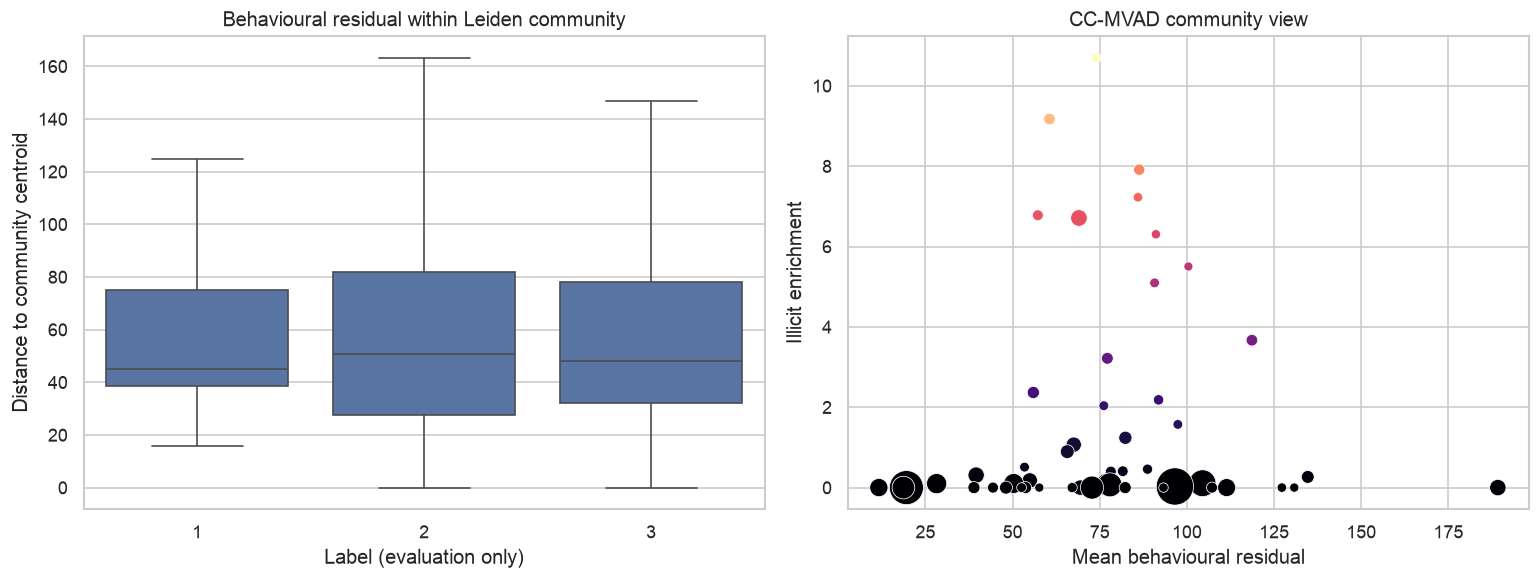

In [12]:
from src.evaluation import cluster_enrichment

community_eval = cluster_enrichment(
    cc_sample['community'].to_numpy(),
    cc_sample['class'],
).reset_index().rename(columns={'cluster': 'community'})
community_eval = community_eval.merge(cc_stats, on='community', how='left')
community_eval['eligible'] = community_eval['cluster_size'] >= 30
print('Top eligible communities by illicit enrichment:')
display(community_eval[community_eval['eligible']].head(15))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=cc_sample, x='class', y='behavioral_residual', ax=axes[0], showfliers=False)
axes[0].set_title('Behavioural residual within Leiden community')
axes[0].set_xlabel('Label (evaluation only)')
axes[0].set_ylabel('Distance to community centroid')
sns.scatterplot(
    data=community_eval[community_eval['cluster_size'] >= 30],
    x='mean_behavioral_residual', y='enrichment', size='cluster_size',
    hue='illicit_rate', palette='magma', sizes=(30, 500), ax=axes[1], legend=False,
)
axes[1].set_title('CC-MVAD community view')
axes[1].set_xlabel('Mean behavioural residual')
axes[1].set_ylabel('Illicit enrichment')
fig.tight_layout()
fig.savefig(OUT / 'cc_mvad_community_evaluation.png', dpi=180, bbox_inches='tight')
plt.show()
community_eval.to_csv(ROOT / 'results' / 'cc_mvad_community_evaluation.csv', index=False)